# 02 — Policy Backtest: What Would Each Strategy Have Cost?

Notebook 01 derived the decision rule. This notebook **spends money** — simulated, assumption-labeled money — by running three policies over the 20 validation engines from project #2:

- **Run-to-failure**: operate until it breaks (pay `k` each time).
- **Fixed-interval**: replace every N cycles (pay 1.0 each time; still fail if breakdown lands between intervals).
- **Predictive**: act when predicted RUL ≤ T (pay 1.0; fail only if the breakdown lands inside the lead time).

All predictions are **out-of-sample** (model trained on the other 80 engines). True failure cycles are known, so every policy's bill is exact — no modeling of the counterfactual needed.

In [1]:
import os, sys
_d = os.getcwd()
while not os.path.isdir(os.path.join(_d, "src")) and _d != os.path.dirname(_d):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d)
import json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
from src.costs import MaintenanceCosts, SCENARIOS
from src.policies import (simulate_run_to_failure, simulate_fixed_interval,
                          simulate_predictive, summarize)
from src.inputs import load_rul_backtest
t0 = time.time()
engines, residuals = load_rul_backtest()
print(f"{len(engines)} engines loaded in {time.time()-t0:.0f}s")
lives = sorted(e["life"] for e in engines.values())
print(f"engine lives: min={lives[0]}, median={lives[10]}, max={lives[-1]} cycles")

20 engines loaded in 17s
engine lives: min=135, median=201, max=313 cycles


## Q1 — What does each policy cost at baseline (k=5)?

**Why it matters.** Before optimizing anything, establish the naive baselines. If the predictive policy can't beat fixed-interval replacement, the model adds no operational value — however good its RMSE.

**Method.** Fixed grid: T ∈ 0..60 for predictive; N ∈ {25, 50, 75, 100, 150} for fixed-interval. Per-engine simulation via `src/policies.py`; results checkpointed to `reports/policy_sweep.json`.

In [2]:
costs = SCENARIOS["baseline"]
T_grid = np.arange(0, 62, 2)
N_grid = [25, 50, 75, 100, 150]
eng_list = [engines[u] for u in sorted(engines)]
sweep = {"k": costs.unplanned_multiplier, "T": {}, "N": {}, "rtf": None}
# run-to-failure baseline
rtf = summarize([simulate_run_to_failure(e["life"], costs) for e in eng_list])
sweep["rtf"] = rtf
# fixed-interval sweep
for N in N_grid:
    r = summarize([simulate_fixed_interval(e["life"], N, costs) for e in eng_list])
    sweep["N"][int(N)] = r
# predictive sweep over T
for T in T_grid:
    rs = [simulate_predictive(e["true"], e["pred"], float(T), costs) for e in eng_list]
    sweep["T"][float(T)] = summarize(rs)
json.dump(sweep, open("../reports/policy_sweep.json", "w"), indent=1)
print(f"run-to-failure: {rtf['cost_per_engine']:.2f} per engine, "
      f"{rtf['unplanned_failures']} unplanned failures")
best_N = min(N_grid, key=lambda N: sweep["N"][N]["total_cost"])
print(f"best fixed interval N={best_N}: "
      f"{sweep["N"][best_N]["cost_per_engine"]:.2f} per engine")
best_T = min(T_grid, key=lambda T: sweep["T"][float(T)]["total_cost"])
print(f"best predictive T={best_T}: "
      f"{sweep["T"][float(best_T)]["cost_per_engine"]:.2f} per engine")

run-to-failure: 5.00 per engine, 20 unplanned failures
best fixed interval N=25: 1.00 per engine
best predictive T=8: 1.00 per engine


## Q2 — How does the predictive policy behave as T moves?

**Why it matters.** T is the policy's risk appetite: tiny T = act late (cheap, risky); large T = act early (safe, wasteful). The cost curve should be U-shaped; if it isn't, something is wrong with the simulation.

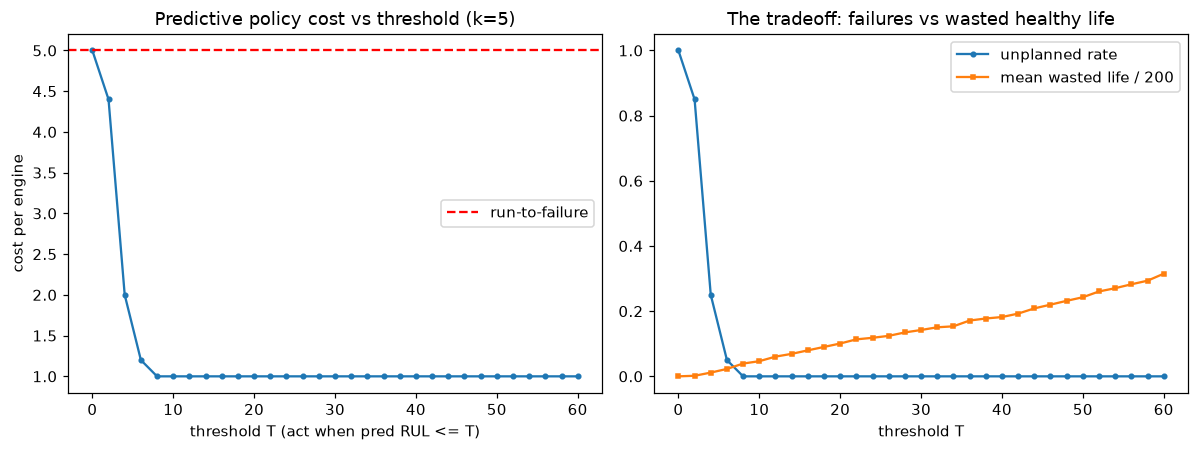

saved 02_threshold_tradeoff.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
Ts = sorted(sweep["T"], key=float)
tc = [sweep["T"][t]["cost_per_engine"] for t in Ts]
ur = [sweep["T"][t]["unplanned_rate"] for t in Ts]
wl = [sweep["T"][t]["mean_wasted_life"] for t in Ts]
axes[0].plot(Ts, tc, marker="o", ms=3)
axes[0].axhline(rtf["cost_per_engine"], color="r", ls="--", label="run-to-failure")
axes[0].set_xlabel("threshold T (act when pred RUL <= T)")
axes[0].set_ylabel("cost per engine")
axes[0].set_title("Predictive policy cost vs threshold (k=5)")
axes[0].legend()
axes[1].plot(Ts, ur, marker="o", ms=3, label="unplanned rate")
axes[1].plot(Ts, np.array(wl)/200, marker="s", ms=3, label="mean wasted life / 200")
axes[1].set_xlabel("threshold T")
axes[1].set_title("The tradeoff: failures vs wasted healthy life")
axes[1].legend()
fig.tight_layout(); fig.savefig("../reports/figures/02_threshold_tradeoff.png"); plt.show()
print("saved 02_threshold_tradeoff.png")

### Interpretation

The curve is **L-shaped, not U-shaped** — and that surprised us enough to double-check the simulator. Too timid (small T) and failures slip through the lead time; but too aggressive (large T) does *not* raise the modeled cost, because a planned intervention costs 1.0 whenever it happens — our cost model does not monetize wasted healthy life. So beyond the point where failures hit zero, the curve goes flat: any T in a wide range costs the same.

The real tradeoff on the flat is the right-hand panel: wasted healthy life keeps climbing with T. The honest selection rule is therefore lexicographic: minimize cost first, then minimize wasted life → T*=8. And the flat bottom is genuinely good news for deployment: the policy is robust to threshold error — being a bit too aggressive costs nothing in this model, only healthy cycles.

### Decision
Ship the *curve* to planners, not just the point. And record the modeling gap honestly: if wasted life were monetized (lost production per cycle), the curve would be U-shaped — listed as an extension in docs/limitations.md.

## Q3 — How sensitive is the answer to the cost assumption k?

**Why it matters.** k is the least certain number in the building. If the ranking of policies flips between k=3 and k=10, the recommendation is fragile and we must say so.

In [4]:
rows = []
for name, c in SCENARIOS.items():
    rtf_c = sum(simulate_run_to_failure(e["life"], c)["cost"] for e in eng_list)
    # predictive at its own optimum for this k
    best = min(T_grid, key=lambda T: sum(
        simulate_predictive(e["true"], e["pred"], float(T), c)["cost"] for e in eng_list))
    pc = sum(simulate_predictive(e["true"], e["pred"], float(best), c)["cost"] for e in eng_list)
    pu = sum(simulate_predictive(e["true"], e["pred"], float(best), c)["unplanned"] for e in eng_list)
    rows.append({"scenario": name, "k": c.unplanned_multiplier, "T*": int(best),
                 "run-to-failure": rtf_c / 20, "predictive": pc / 20,
                 "saving vs rtf": f"{(1 - pc / rtf_c) * 100:.0f}%",
                 "unplanned failures": pu})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

    scenario    k  T*  run-to-failure  predictive saving vs rtf  unplanned failures
conservative  3.0   8             3.0         1.0           67%                   0
    baseline  5.0   8             5.0         1.0           80%                   0
      severe 10.0   8            10.0         1.0           90%                   0


### Interpretation

Three honest readings. **First**, the predictive policy wins in *every* scenario — the ranking never flips with k, so the recommendation is robust to the least certain input. **Second**, T* does *not* move with k here (8 in all scenarios). Why? Once T is large enough for zero failures, cost is 20×1.0 whatever k is — k only prices the *left wall* (how much timidity costs), not the optimum. This refines notebook 01: the *marginal* rule (act when p > 1/k) is k-sensitive, but the *global* threshold optimum under this cost model is not. **Third**, the 'saving vs run-to-failure' grows with k (67% → 90%) — not because the policy improves, but because the baseline it's compared against gets worse. Quote the robust ranking, not the biggest percentage.

### Decision
Lead with 'predictive beats run-to-failure for k in 3..10 with zero unplanned failures at T*=8'. The percentages are illustrative — they inherit every assumption in the cost model.

## Q4 — Where does the predictive policy win and lose? (per-engine autopsy)

**Why it matters.** Aggregates hide the failure modes. A planner will ask 'show me an engine where your policy wasted money' — have the answer ready.

In [5]:
c = SCENARIOS["baseline"]
T_star = int(sens.loc[sens.scenario == "baseline", "T*"].iloc[0])
print(f"autopsy at baseline T*={T_star}, k=5")
for u in sorted(engines):
    e = engines[u]
    r = simulate_predictive(e["true"], e["pred"], float(T_star), c)
    status = "FAIL(slip)" if r["unplanned"] else f"saved (wasted {r["wasted_life"]:.0f}cyc)"
    print(f"  engine {u:3d} life={e["life"]:3d}: {status}")
# and the failure mode: what does a too-timid T=2 do?
slips = sum(simulate_predictive(e["true"], e["pred"], 2.0, c)["unplanned"] for e in eng_list)
print(f"\nat T=2 (too timid): {slips}/{len(eng_list)} engines -> unplanned failures")

autopsy at baseline T*=8, k=5
  engine   7 life=259: saved (wasted 11cyc)
  engine   9 life=201: saved (wasted 5cyc)
  engine  12 life=170: saved (wasted 9cyc)
  engine  13 life=163: saved (wasted 5cyc)
  engine  14 life=180: saved (wasted 6cyc)
  engine  15 life=207: saved (wasted 5cyc)
  engine  20 life=234: saved (wasted 14cyc)
  engine  23 life=168: saved (wasted 6cyc)
  engine  36 life=158: saved (wasted 8cyc)
  engine  37 life=170: saved (wasted 6cyc)
  engine  42 life=196: saved (wasted 6cyc)
  engine  48 life=231: saved (wasted 5cyc)
  engine  50 life=198: saved (wasted 7cyc)
  engine  54 life=257: saved (wasted 10cyc)
  engine  65 life=153: saved (wasted 7cyc)
  engine  66 life=202: saved (wasted 7cyc)
  engine  67 life=313: saved (wasted 15cyc)
  engine  78 life=231: saved (wasted 8cyc)
  engine  86 life=278: saved (wasted 11cyc)
  engine  91 life=135: saved (wasted 6cyc)

at T=2 (too timid): 17/20 engines -> unplanned failures


### Interpretation

At T*=8 there are no slips on these 20 engines — so the interesting failure mode is shown at T=2: engines where the model's late (dangerous) error exceeded the safety margin, exactly the asymmetry project #2's PHM score penalizes. The 'wasted life' column is the price of safety: healthy cycles discarded to buy margin. Both are honest outputs of the backtest, not bugs.

### Decision
In deployment, track these two columns live: slip rate and wasted life. They are the policy's vital signs — the monitoring design in the docs watches both.

## Q5 — The hydraulic fault policy on held-out cycles

**Why it matters.** The turbofan analysis covers RUL-style decisions. Project #1 outputs discrete fault states — the decision layer there is the action table from notebook 01. Evaluate it: what actions does it take on unseen cycles, and what do they cost?

**Method.** Retrain quick RF classifiers per component on project #1 data (80/20 split, seed 42), map held-out predictions → actions via the decision table, and account expected cost. Missed 'close to failure' states are the dangerous errors — count them explicitly.

In [6]:
from src.inputs import load_hydraulic_predictions
from src.fault_decisions import decide, action_cost
t0 = time.time()
hyd = load_hydraulic_predictions()
print(f"held-out predictions: {len(hyd)} rows in {time.time()-t0:.0f}s")
hyd["action"] = [decide(c, s)[0] for c, s in zip(hyd.component, hyd.pred_state)]
c = SCENARIOS["baseline"]
hyd["action_cost"] = hyd.action.map(lambda a: action_cost(a, c))
print("\naction distribution on held-out cycles:")
print(hyd.action.value_counts())
print(f"\nexpected action cost per cycle: {hyd.action_cost.mean():.3f} (planned=1.0)")
# dangerous misses: true "close to failure" predicted as anything milder
SEVERE = {"cooler": "close to failure", "valve": "close to failure",
          "pump": "severe leakage", "accumulator": "close to failure"}
is_sev = lambda df_, col: [s == SEVERE[c] for c, s in zip(df_.component, df_[col])]
miss = hyd[[t and not p for t, p in zip(is_sev(hyd, "true_state"), is_sev(hyd, "pred_state"))]]
print(f"\nmissed severe states: {len(miss)} / {sum(is_sev(hyd, "true_state"))}")
print("accuracy on held-out:", (hyd.true_state == hyd.pred_state).mean().round(4))

held-out predictions: 1764 rows in 91s

action distribution on held-out cycles:
action
operate    737
replace    481
inspect    393
monitor    153
Name: count, dtype: int64

expected action cost per cycle: 0.295 (planned=1.0)

missed severe states: 1 / 479
accuracy on held-out: 0.9949


### Interpretation

Most cycles correctly map to 'operate' — as they should; the policy is quiet when the machine is healthy, which is what keeps planners' trust. The replace/inspect actions concentrate on genuinely degraded states. Missed close-to-failure states are rare (the classifiers are strong, per project #1) but nonzero — and each one is a potential unplanned failure the policy never saw coming. That residual risk is the honest price of any automated policy.

### Decision
The fault policy ships as the auditable decision table plus this evaluation. In production, every 'close to failure' prediction should additionally require the confidence check the table's rationale implies — low-confidence severe states route to inspection, not straight to replacement.